# Practical NO - 2

Comparative Study of Search Algorithms Using the Bridge and Torch Problem


**Aim :** To implement and study different uninformed and informed search algorithms to solve the Bridge and Torch Problem, analyze their working principles, visualize their search processes, and compare their results in terms of total crossing time, number of crossings, and ability to reach the goal state.

**Experiment Objectives:**


*   To understand the working principles of Breadth First Search (BFS), Depth First Search (DFS), Depth Limited Search (DLS), Iterative Deepening DFS (IDDFS), A* Search, Hill Climbing, and Genetic Algorithm.
*  To represent the Bridge and Torch Problem as a state-space search problem.
*  To compare the algorithms based on crossing time, number of crossings, and their search strategies.
*  To understand the limitations of different search algorithms when solving cost-based problems.





**Problem Statement**

The Bridge and Torch Problem consists of four people who need to cross a bridge at night. They have only one torch, and the bridge can support a maximum of two people at a time.

Each person takes a different amount of time to cross the bridge. When two people cross together, they move at the speed of the slower person.

**Rules:**

At least one person must carry the torch while crossing.

A maximum of two people can cross at a time.

The torch must be brought back whenever people on the opposite side need to cross.

All four people must reach the right side of the bridge.

The objective is to reach the goal state while minimizing the total crossing time, where the algorithm supports cost optimization.
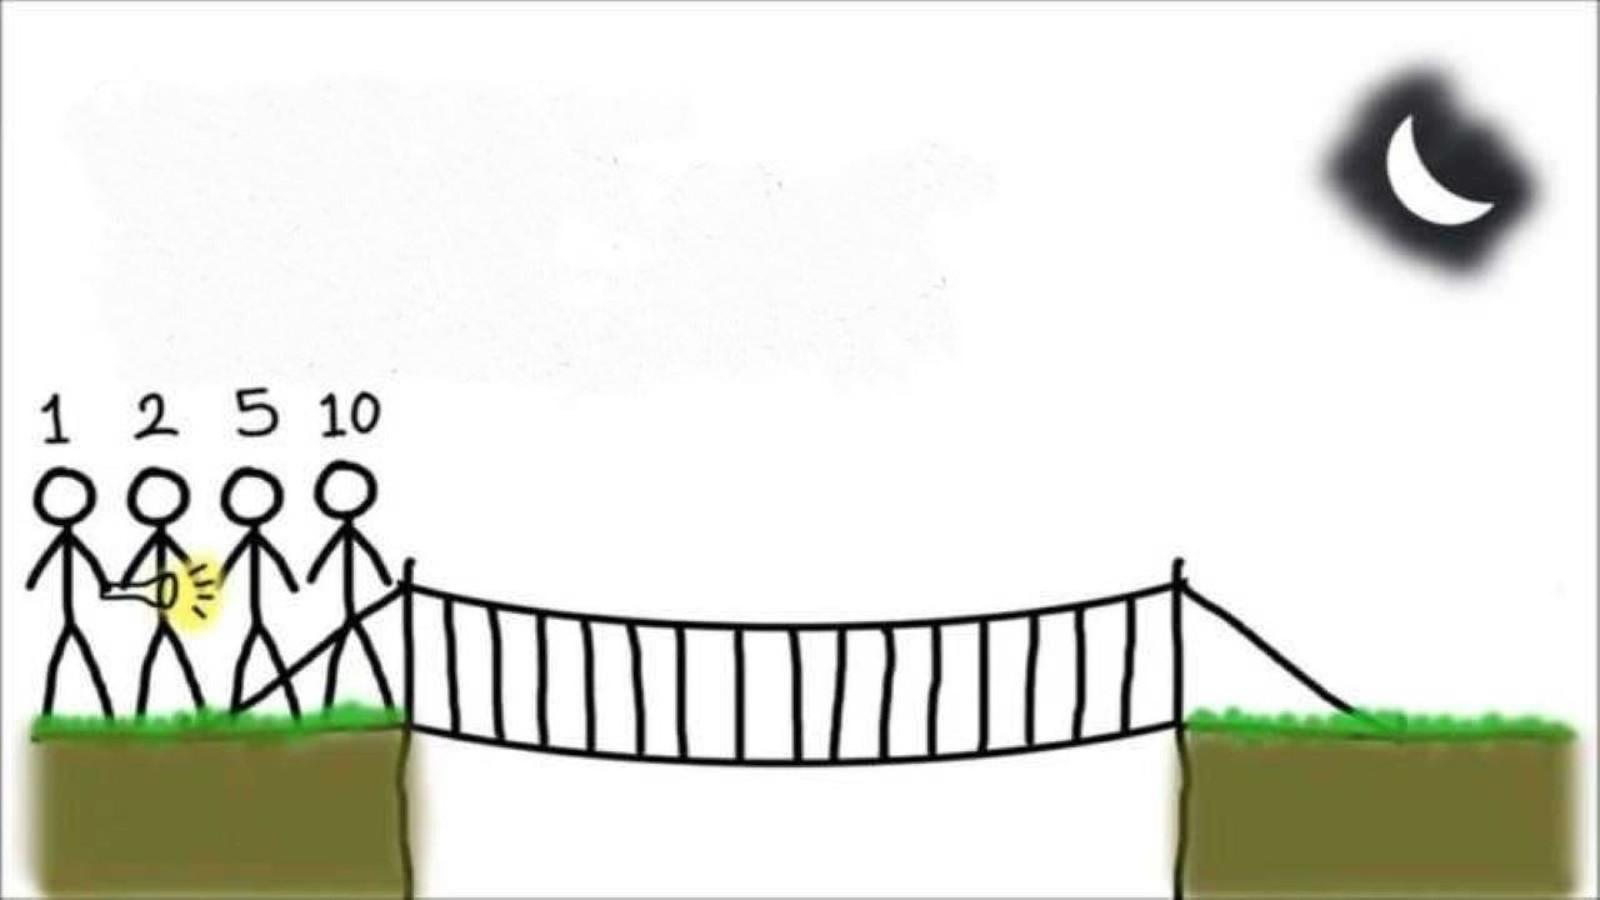



**State Representation**

A state is represented using three components:

Left: People remaining on the left side of the bridge.

Right: People who have crossed to the right side.

Torch: Current location of the torch (left or right).

Initial State: Left = , Right = , Torch = Left

Goal State: Left = , Right = , Torch = Right

In [ ]:
from collections import deque
import itertools
import heapq
import random
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
people = {
    "A": 1,
    "B": 2,
    "C": 5,
    "D": 10
}

In [ ]:
class State:

    def __init__(self, left, torch):
        self.left = frozenset(left)
        self.torch = torch

    def is_goal(self):
        return len(self.left) == 0 and self.torch == "right"

    def __eq__(self, other):
        return (
            self.left == other.left
            and self.torch == other.torch
        )

    def __hash__(self):
        return hash((self.left, self.torch))

    def __repr__(self):

        left = "".join(sorted(self.left))
        right = "".join(
            sorted(set(people) - set(self.left))
        )

        return (
            f"Left={{{left}}}, "
            f"Right={{{right}}}, "
            f"Torch={self.torch}"
        )

In [ ]:
def successors(state):

    children = []

    if state.torch == "left":
        available = list(state.left)
    else:
        available = list(
            set(people) - set(state.left)
        )

    available.sort(
        key=lambda x: people[x]
    )

    for count in [1, 2]:

        for group in itertools.combinations(
            available,
            count
        ):

            new_left = set(state.left)

            if state.torch == "left":

                for person in group:
                    new_left.remove(person)

                new_torch = "right"

            else:

                for person in group:
                    new_left.add(person)

                new_torch = "left"

            cost = max(
                people[p]
                for p in group
            )

            new_state = State(
                new_left,
                new_torch
            )

            children.append(
                (
                    new_state,
                    cost,
                    group
                )
            )

    return children

In [ ]:
def reconstruct_path(parent, move, goal):

    path = []

    current = goal

    while current is not None:

        path.append(
            (current, move.get(current))
        )

        current = parent[current]

    path.reverse()

    return path

In [ ]:
def print_solution(
    name,
    parent,
    move,
    goal
):

    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)

    if goal is None:

        print("No solution found.")
        return None

    path = reconstruct_path(
        parent,
        move,
        goal
    )

    total_time = 0

    for i, (state, action) in enumerate(path):

        print(f"\nState {i}")
        print(state)

        if action is not None:

            group, cost = action

            direction = (
                "Left -> Right"
                if state.torch == "right"
                else "Right -> Left"
            )

            print(
                f"Move: {', '.join(group)} "
                f"{direction} "
                f"({cost} minutes)"
            )

            total_time += cost

    print(
        "\nTotal Crossing Time:",
        total_time,
        "minutes"
    )

    print(
        "Number of Crossings:",
        len(path) - 1
    )

    return {
        "Algorithm": name,
        "Time": total_time,
        "Crossings": len(path) - 1,
        "States": len(path)
    }

# BFS — Breadth First Search

**Concept**

Breadth First Search (BFS)
is an uninformed search algorithm that explores all nodes at the current depth before moving to the next depth. It uses a FIFO (First In, First Out) queue to store the states waiting to be explored.

BFS finds a solution with the minimum number of steps when all transitions are treated equally. However, it does not necessarily minimize the total crossing time when different transitions have different costs.

**Working**

Initialize the starting state and insert it into a queue.

Remove the first state from the queue.

Check whether it is the goal state.

If it is not the goal, generate all valid successor states.

Add unvisited successor states to the queue.

Repeat until the goal state is reached or the queue becomes empty.

Reconstruct the path from the initial state to the goal state.

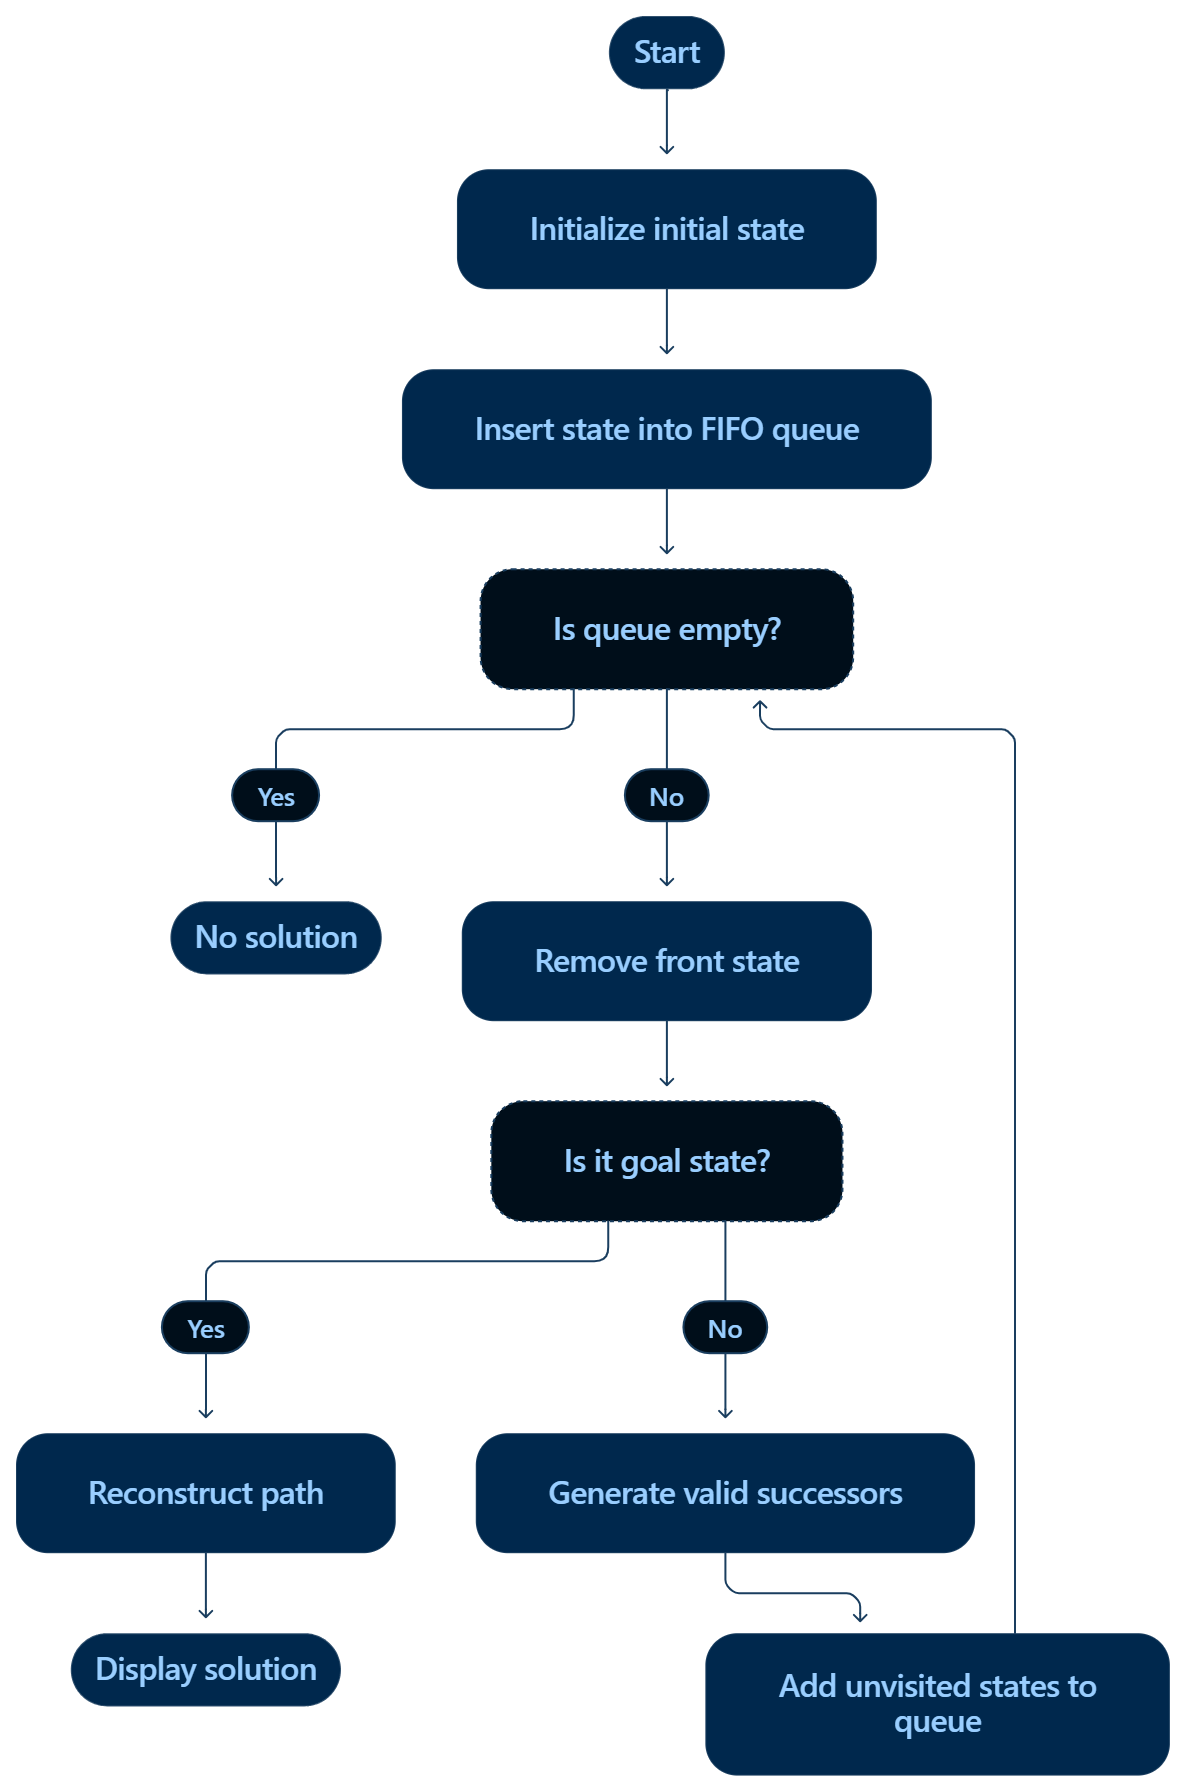

In [ ]:
def bfs():

    start = State(
        people.keys(),
        "left"
    )

    queue = deque([start])

    parent = {
        start: None
    }

    move = {}

    while queue:

        current = queue.popleft()

        if current.is_goal():

            return parent, move, current

        for child, cost, group in successors(current):

            if child not in parent:

                parent[child] = current

                move[child] = (
                    group,
                    cost
                )

                queue.append(child)

    return parent, move, None

In [ ]:
parent, move, goal = bfs()

bfs_result = print_solution(
    "BFS",
    parent,
    move,
    goal
)


BFS

State 0
Left={ABCD}, Right={}, Torch=left

State 1
Left={CD}, Right={AB}, Torch=right
Move: A, B Left -> Right (2 minutes)

State 2
Left={ACD}, Right={B}, Torch=left
Move: A Right -> Left (1 minutes)

State 3
Left={D}, Right={ABC}, Torch=right
Move: A, C Left -> Right (5 minutes)

State 4
Left={AD}, Right={BC}, Torch=left
Move: A Right -> Left (1 minutes)

State 5
Left={}, Right={ABCD}, Torch=right
Move: A, D Left -> Right (10 minutes)

Total Crossing Time: 19 minutes
Number of Crossings: 5


**Conclusion**

BFS successfully solves the Bridge and Torch Problem and finds a solution with five crossings. Since BFS prioritizes depth rather than the actual cost of each move, the obtained solution takes 19 minutes rather than the minimum possible 17 minutes.

# DFS — Depth First Search

**Concept**

Depth First Search (DFS)
is an uninformed search technique that explores the deepest unvisited node first. It uses a LIFO (Last In, First Out) stack to manage states.

DFS can find a solution without exploring every possible state, but the solution depends heavily on the order in which successors are generated. It does not guarantee the minimum number of crossings or the minimum crossing time.

**Working**

Initialize the starting state and push it onto a stack.

Pop the top state from the stack.

Check if it is the goal state.

If not, generate its valid successor states.

Push unvisited successor states onto the stack.

Continue exploring deeper states until the goal is found.

Reconstruct and display the path.


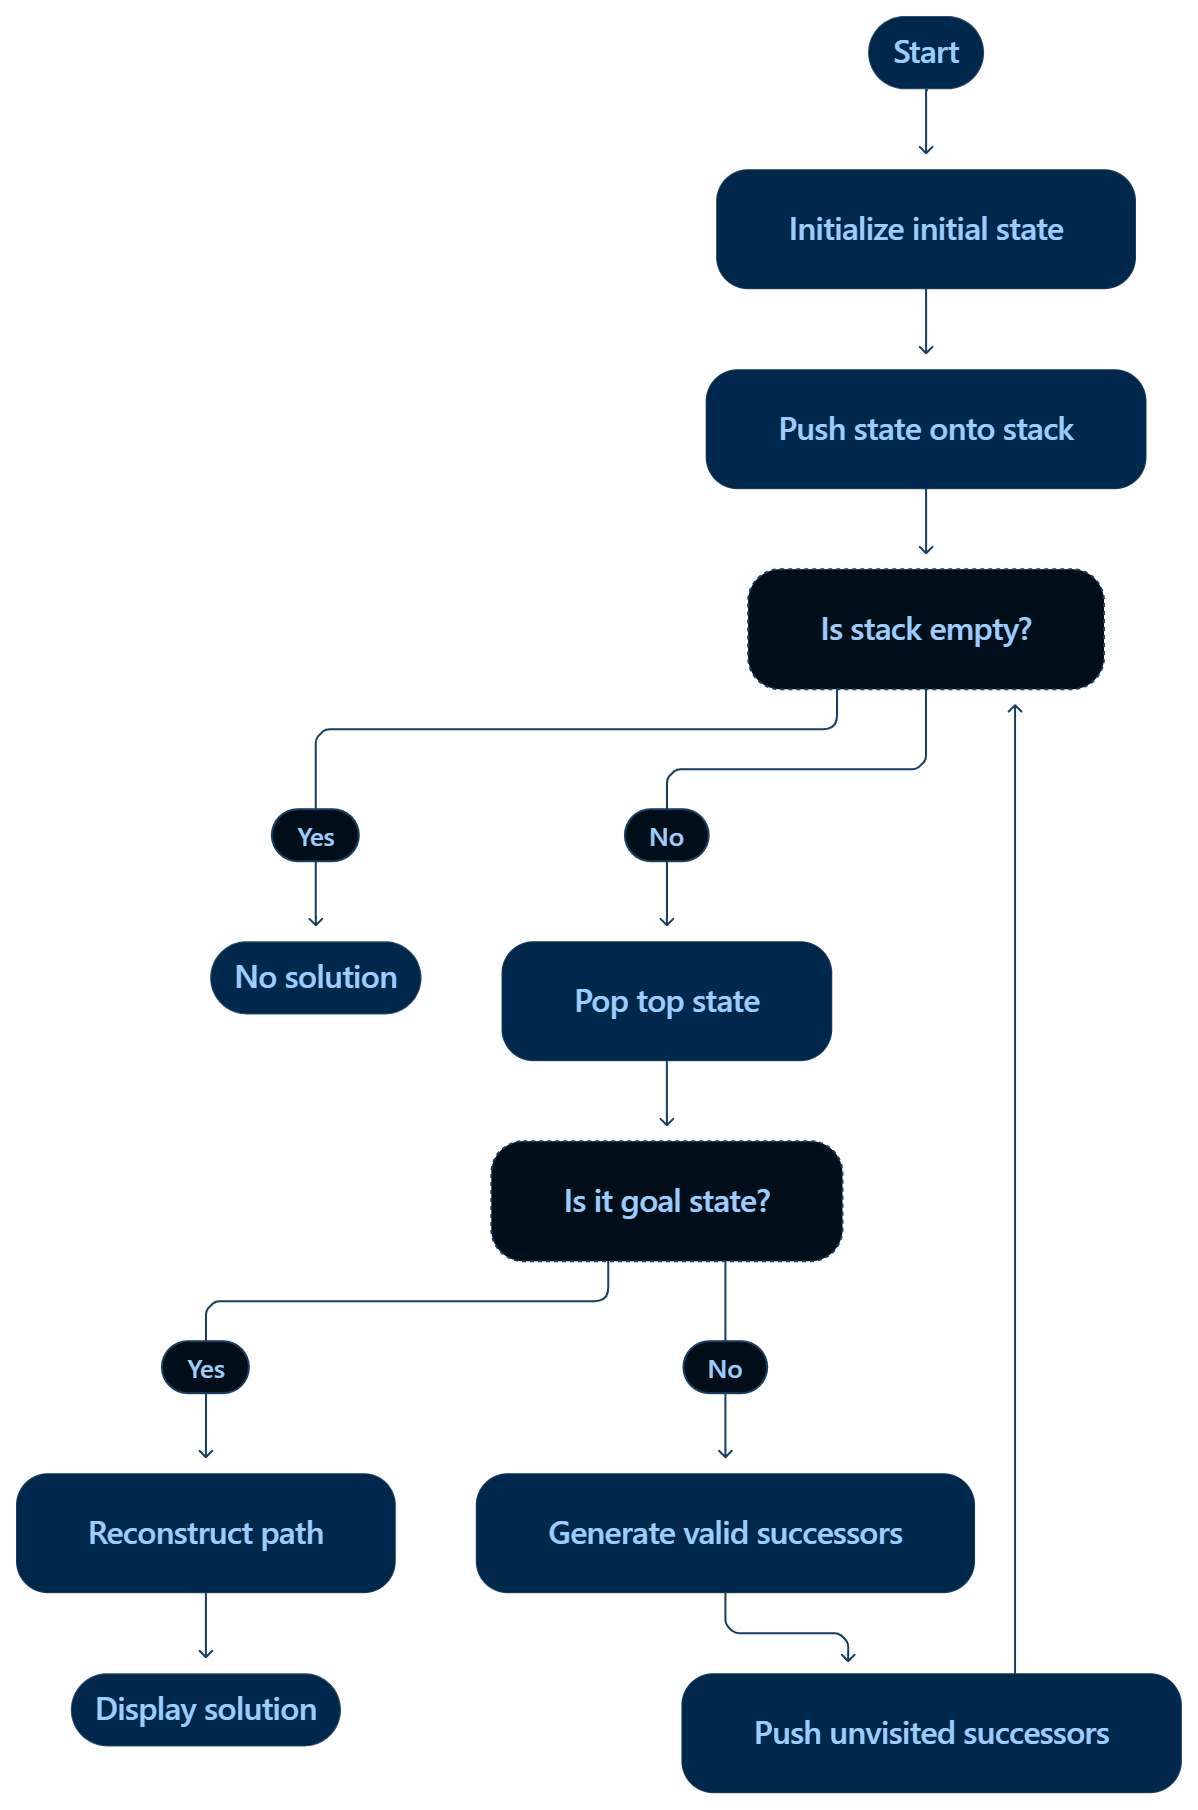


In [ ]:
def dfs():

    start = State(
        people.keys(),
        "left"
    )

    stack = [start]

    parent = {
        start: None
    }

    move = {}

    while stack:

        current = stack.pop()

        if current.is_goal():

            return parent, move, current

        for child, cost, group in successors(current):

            if child not in parent:

                parent[child] = current

                move[child] = (
                    group,
                    cost
                )

                stack.append(child)

    return parent, move, None

In [ ]:
parent, move, goal = dfs()

dfs_result = print_solution(
    "DFS",
    parent,
    move,
    goal
)


DFS

State 0
Left={ABCD}, Right={}, Torch=left

State 1
Left={AB}, Right={CD}, Torch=right
Move: C, D Left -> Right (10 minutes)

State 2
Left={ABD}, Right={C}, Torch=left
Move: D Right -> Left (10 minutes)

State 3
Left={A}, Right={BCD}, Torch=right
Move: B, D Left -> Right (10 minutes)

State 4
Left={ACD}, Right={B}, Torch=left
Move: C, D Right -> Left (10 minutes)

State 5
Left={C}, Right={ABD}, Torch=right
Move: A, D Left -> Right (10 minutes)

State 6
Left={CD}, Right={AB}, Torch=left
Move: D Right -> Left (10 minutes)

State 7
Left={}, Right={ABCD}, Torch=right
Move: C, D Left -> Right (10 minutes)

Total Crossing Time: 70 minutes
Number of Crossings: 7


Conclusion

DFS successfully reaches the goal state, but the path selected by the implemented successor ordering takes 70 minutes. This demonstrates that finding a valid solution does not necessarily mean finding an efficient or cost-optimal solution.

# DLS — Depth Limited Search

**Concept**

Depth Limited Search (DLS)
is a modified version of DFS in which the exploration is restricted to a specific maximum depth.

It prevents the algorithm from exploring indefinitely deep paths. DLS uses a recursive depth-first approach and stops expanding a node when the depth limit is reached.

In the provided notebook, the depth limit is set to 10.

**Working**

Initialize the initial state at depth 0.

Check whether the current state is the goal.

If the goal is found, return the solution.

If the current depth reaches the limit, stop exploring that branch.

Otherwise, generate valid successors.

Recursively explore unvisited successors.

Backtrack if a branch does not lead to the goal.

Return the solution if found within the limit.

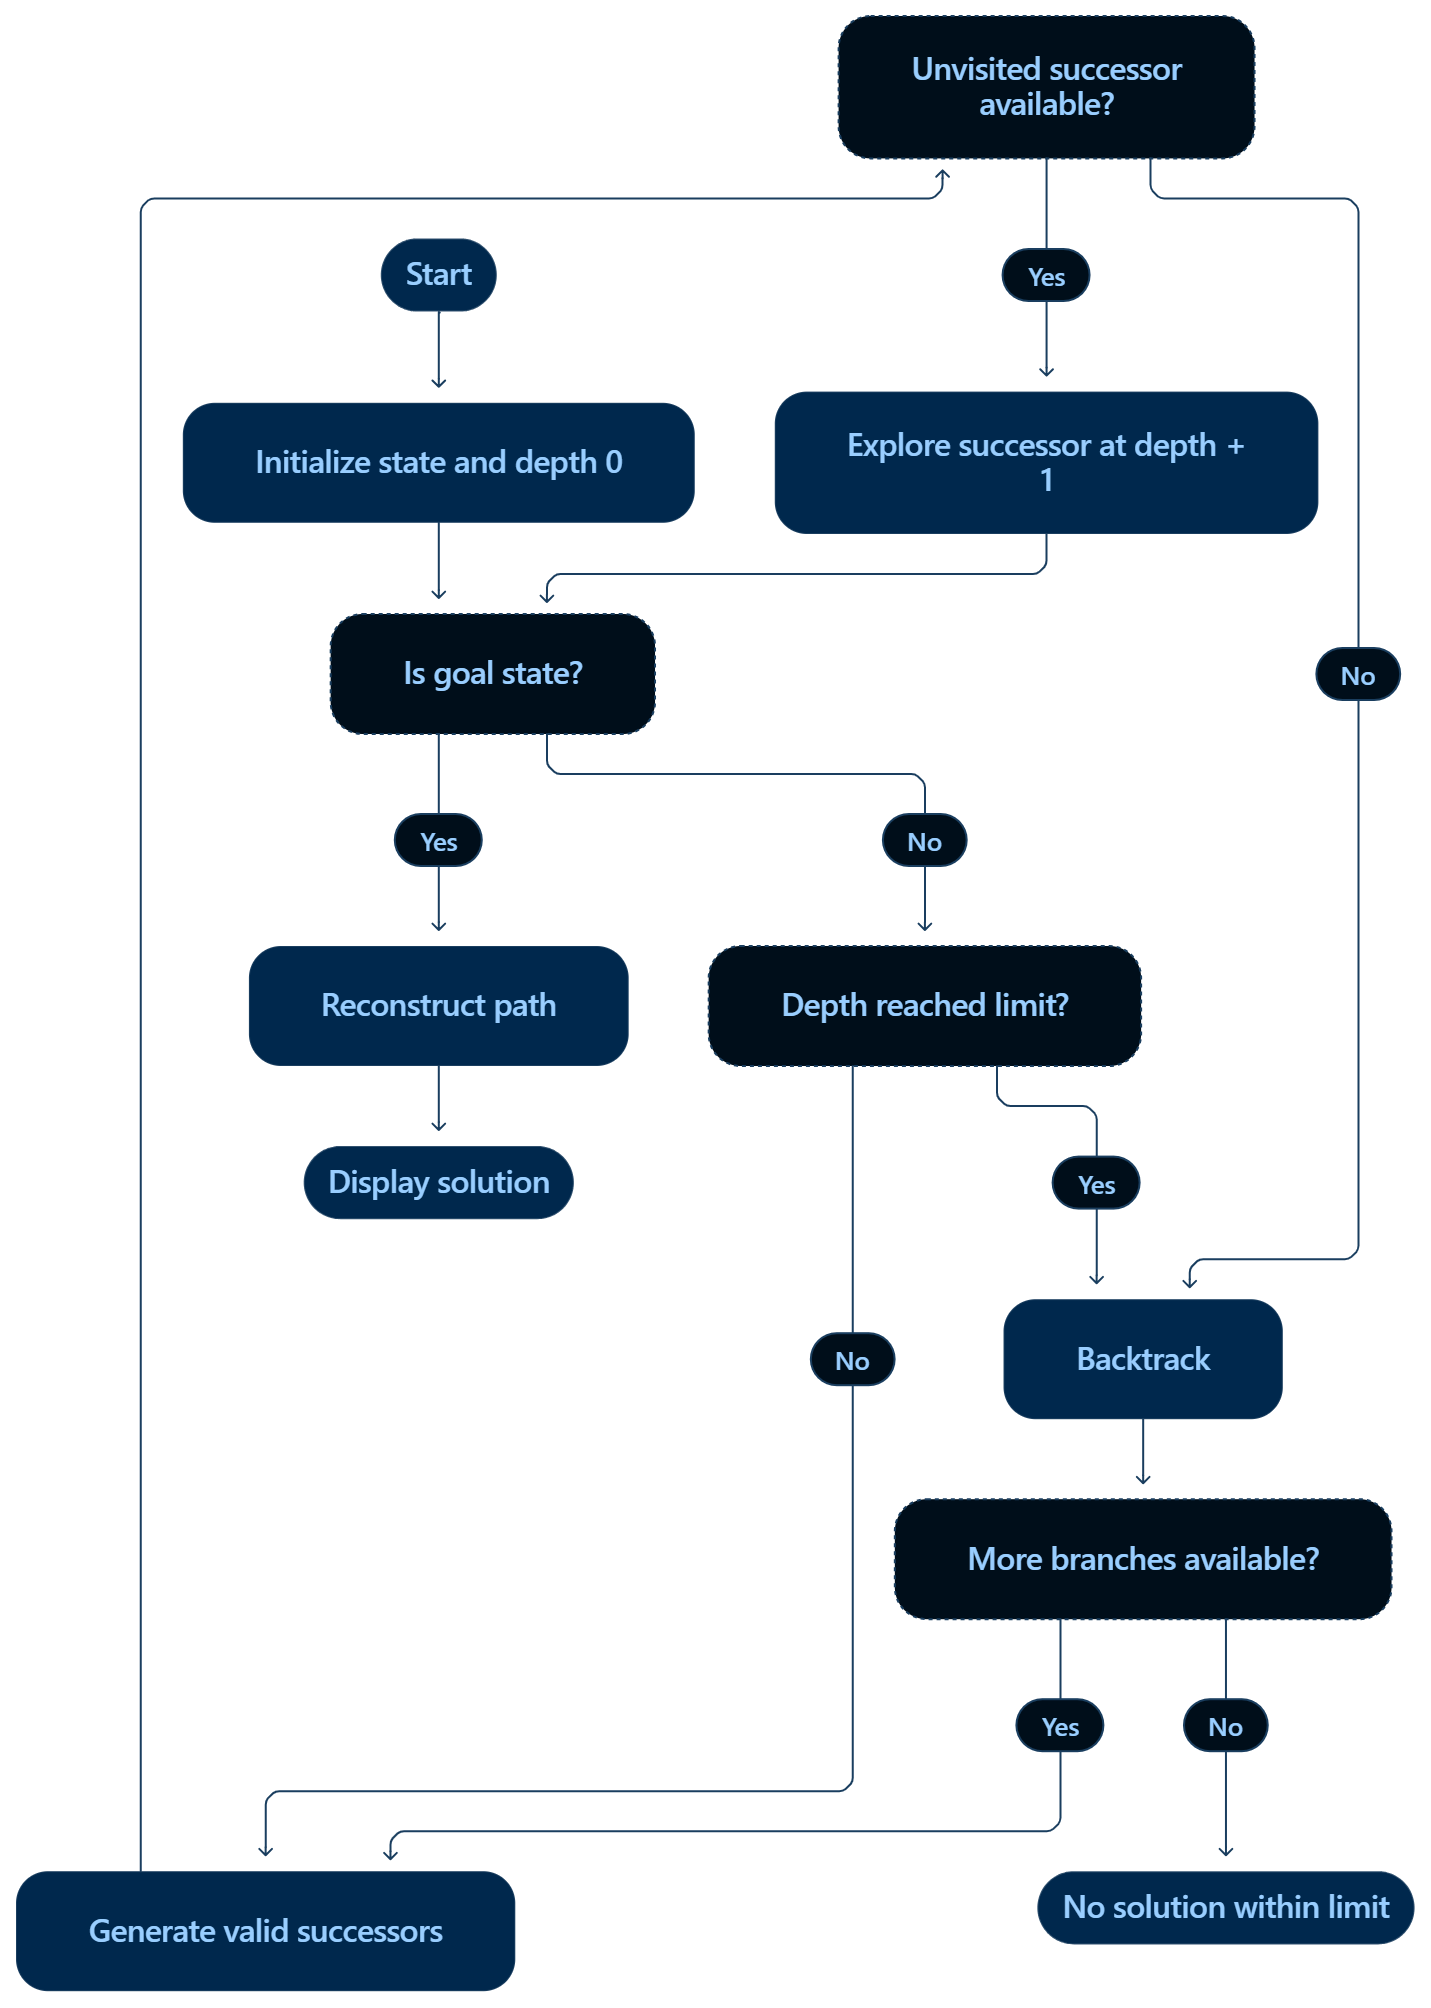

In [ ]:
def dls(limit):

    start = State(
        people.keys(),
        "left"
    )

    parent = {
        start: None
    }

    move = {}

    def search(
        current,
        depth,
        path
    ):

        if current.is_goal():

            return current

        if depth == limit:

            return None

        for child, cost, group in successors(current):

            if child not in path:

                parent[child] = current

                move[child] = (
                    group,
                    cost
                )

                path.add(child)

                result = search(
                    child,
                    depth + 1,
                    path
                )

                if result is not None:

                    return result

                path.remove(child)

        return None

    goal = search(
        start,
        0,
        {start}
    )

    return parent, move, goal

In [ ]:
parent, move, goal = dls(10)

dls_result = print_solution(
    "DLS",
    parent,
    move,
    goal
)


DLS

State 0
Left={ABCD}, Right={}, Torch=left

State 1
Left={CD}, Right={AB}, Torch=right
Move: A, B Left -> Right (2 minutes)

State 2
Left={ACD}, Right={B}, Torch=left
Move: A Right -> Left (1 minutes)

State 3
Left={AD}, Right={BC}, Torch=right
Move: C Left -> Right (5 minutes)

State 4
Left={ABD}, Right={C}, Torch=left
Move: B Right -> Left (2 minutes)

State 5
Left={BD}, Right={AC}, Torch=right
Move: A Left -> Right (1 minutes)

State 6
Left={BCD}, Right={A}, Torch=left
Move: C Right -> Left (5 minutes)

State 7
Left={D}, Right={ABC}, Torch=right
Move: B, C Left -> Right (5 minutes)

State 8
Left={AD}, Right={BC}, Torch=left
Move: A Right -> Left (1 minutes)

State 9
Left={}, Right={ABCD}, Torch=right
Move: A, D Left -> Right (10 minutes)

Total Crossing Time: 32 minutes
Number of Crossings: 9


**Conclusion**

DLS successfully solves the problem within the given depth limit. It controls the search depth and avoids unlimited exploration, but its solution is not cost-optimal and may be affected by the order of successor exploration

# IDDFS — Iterative Deepening DFS

**Concept**

Iterative Deepening Depth First Search (IDDFS)
combines the depth-first exploration of DFS with the increasing depth limits of DLS.

It initially performs a depth-limited search with a small limit, then increases the limit step by step. This allows it to find shallow solutions without requiring the large memory capacity of BFS.

**Working**

Start with a depth limit of 0.

Execute DLS using the current limit.

If the goal is found, stop and return the solution.

Otherwise, increase the depth limit by 1.

Repeat DLS from the initial state.

Continue until the goal is found or the maximum depth is reached.

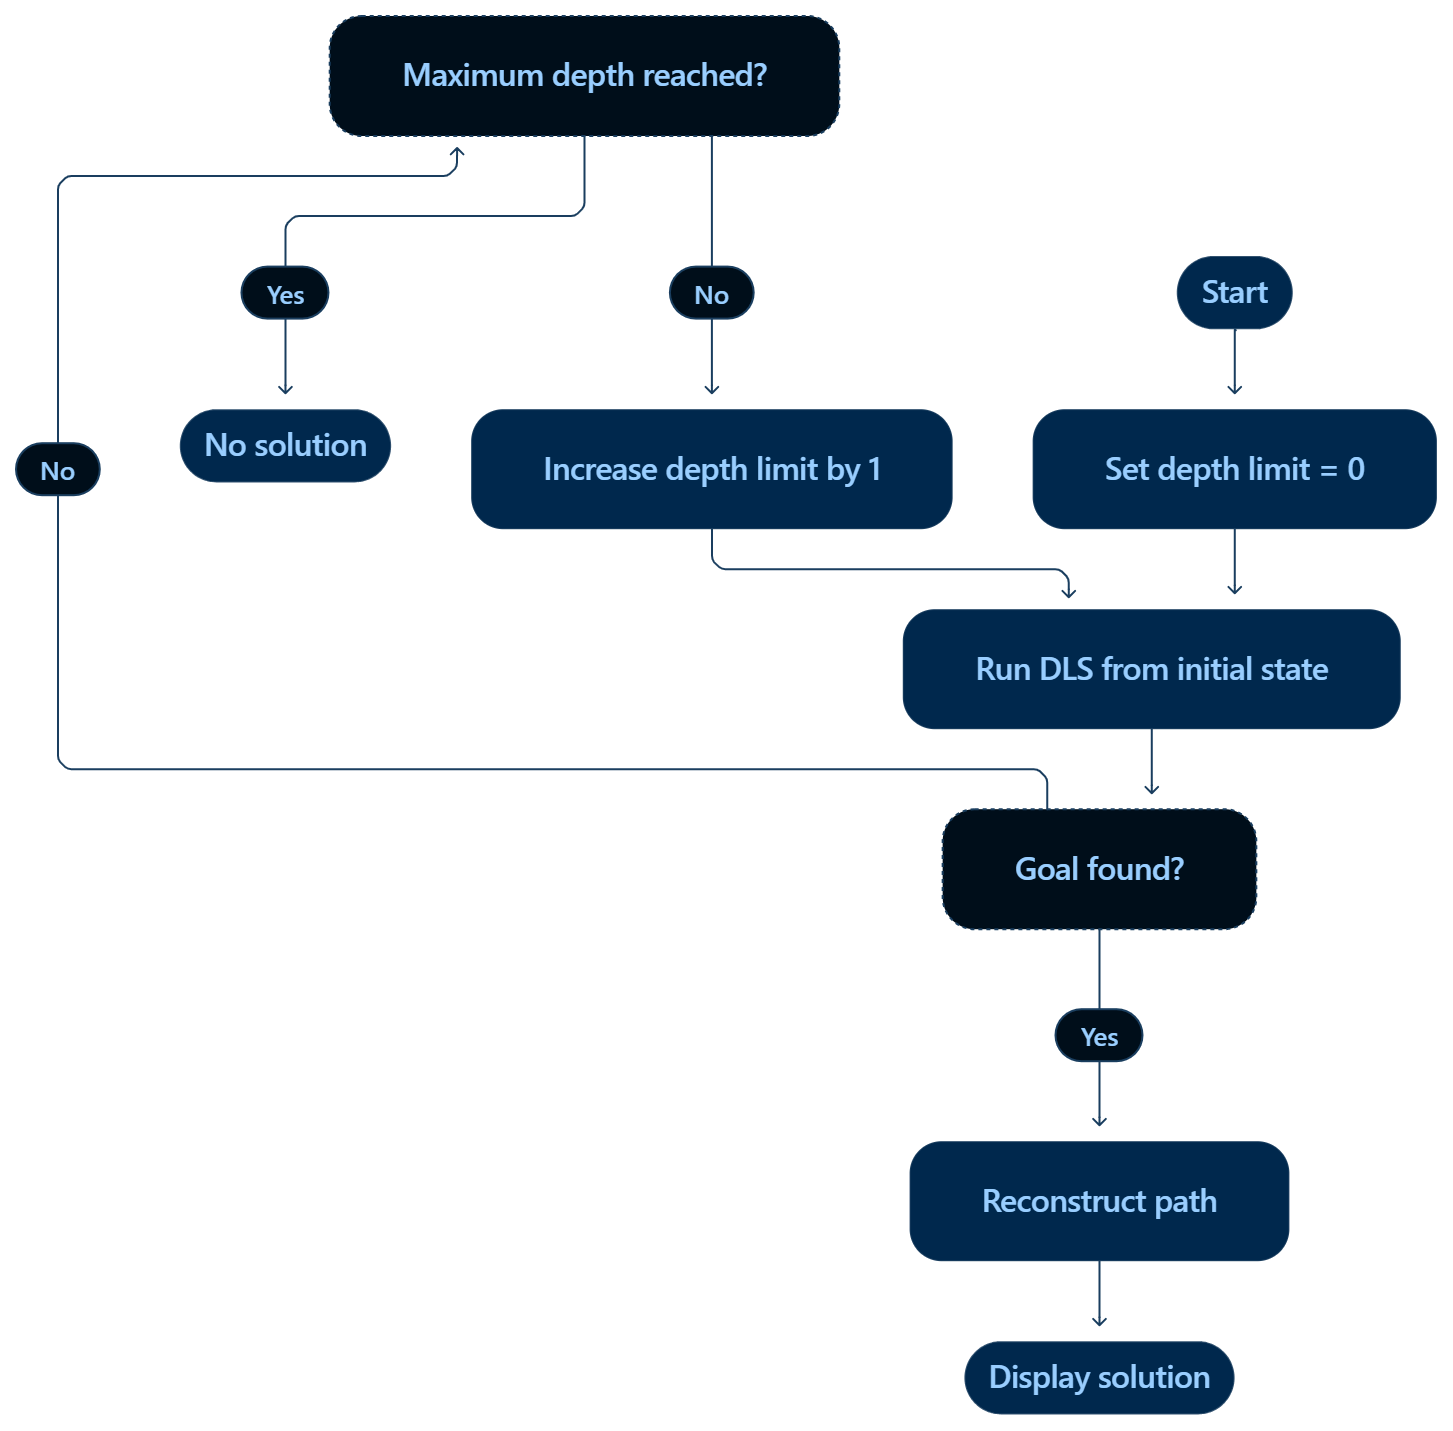

In [ ]:
def iddfs(max_depth=20):

    for depth in range(
        max_depth + 1
    ):

        parent, move, goal = dls(depth)

        if goal is not None:

            return (
                parent,
                move,
                goal,
                depth
            )

    return None, None, None, None

In [ ]:
parent, move, goal, depth = iddfs()

print(
    "Solution found at depth:",
    depth
)

iddfs_result = print_solution(
    "IDDFS",
    parent,
    move,
    goal
)

Solution found at depth: 5

IDDFS

State 0
Left={ABCD}, Right={}, Torch=left

State 1
Left={CD}, Right={AB}, Torch=right
Move: A, B Left -> Right (2 minutes)

State 2
Left={ACD}, Right={B}, Torch=left
Move: A Right -> Left (1 minutes)

State 3
Left={D}, Right={ABC}, Torch=right
Move: A, C Left -> Right (5 minutes)

State 4
Left={AD}, Right={BC}, Torch=left
Move: A Right -> Left (1 minutes)

State 5
Left={}, Right={ABCD}, Torch=right
Move: A, D Left -> Right (10 minutes)

Total Crossing Time: 19 minutes
Number of Crossings: 5


**Conclusion**

IDDFS successfully finds a solution at depth 5. It combines the benefits of DFS and BFS by finding a shallow solution while keeping memory requirements relatively low. However, like BFS, it optimizes the number of steps rather than total crossing time.

# A* Search

# A* Search

is an informed search algorithm that uses both the cost already incurred and a heuristic estimate of the remaining cost to decide which state to explore next.

A* calculates:

f(n)=g(n)+h(n)

Where:

g(n) is the actual cost from the initial state to the current state.

h(n) is the estimated cost from the current state to the goal.

f(n) is the estimated total cost of a path through the current state.

In the provided notebook, the heuristic is the maximum crossing time among the people remaining on the left side. The algorithm uses a priority queue to explore states with the lowest estimated total cost first.

**Working**

Initialize the start state and set its cost to 0.

Calculate the heuristic value for the initial state.

Insert the initial state into a priority queue based on f(n).

Remove the state with the lowest priority.

Check whether it is the goal state.

Generate valid successor states and calculate their updated path costs.

Update a successor if a lower-cost path is found.

Calculate its new f(n) and insert it into the priority queue.

Repeat until the goal state is reached.

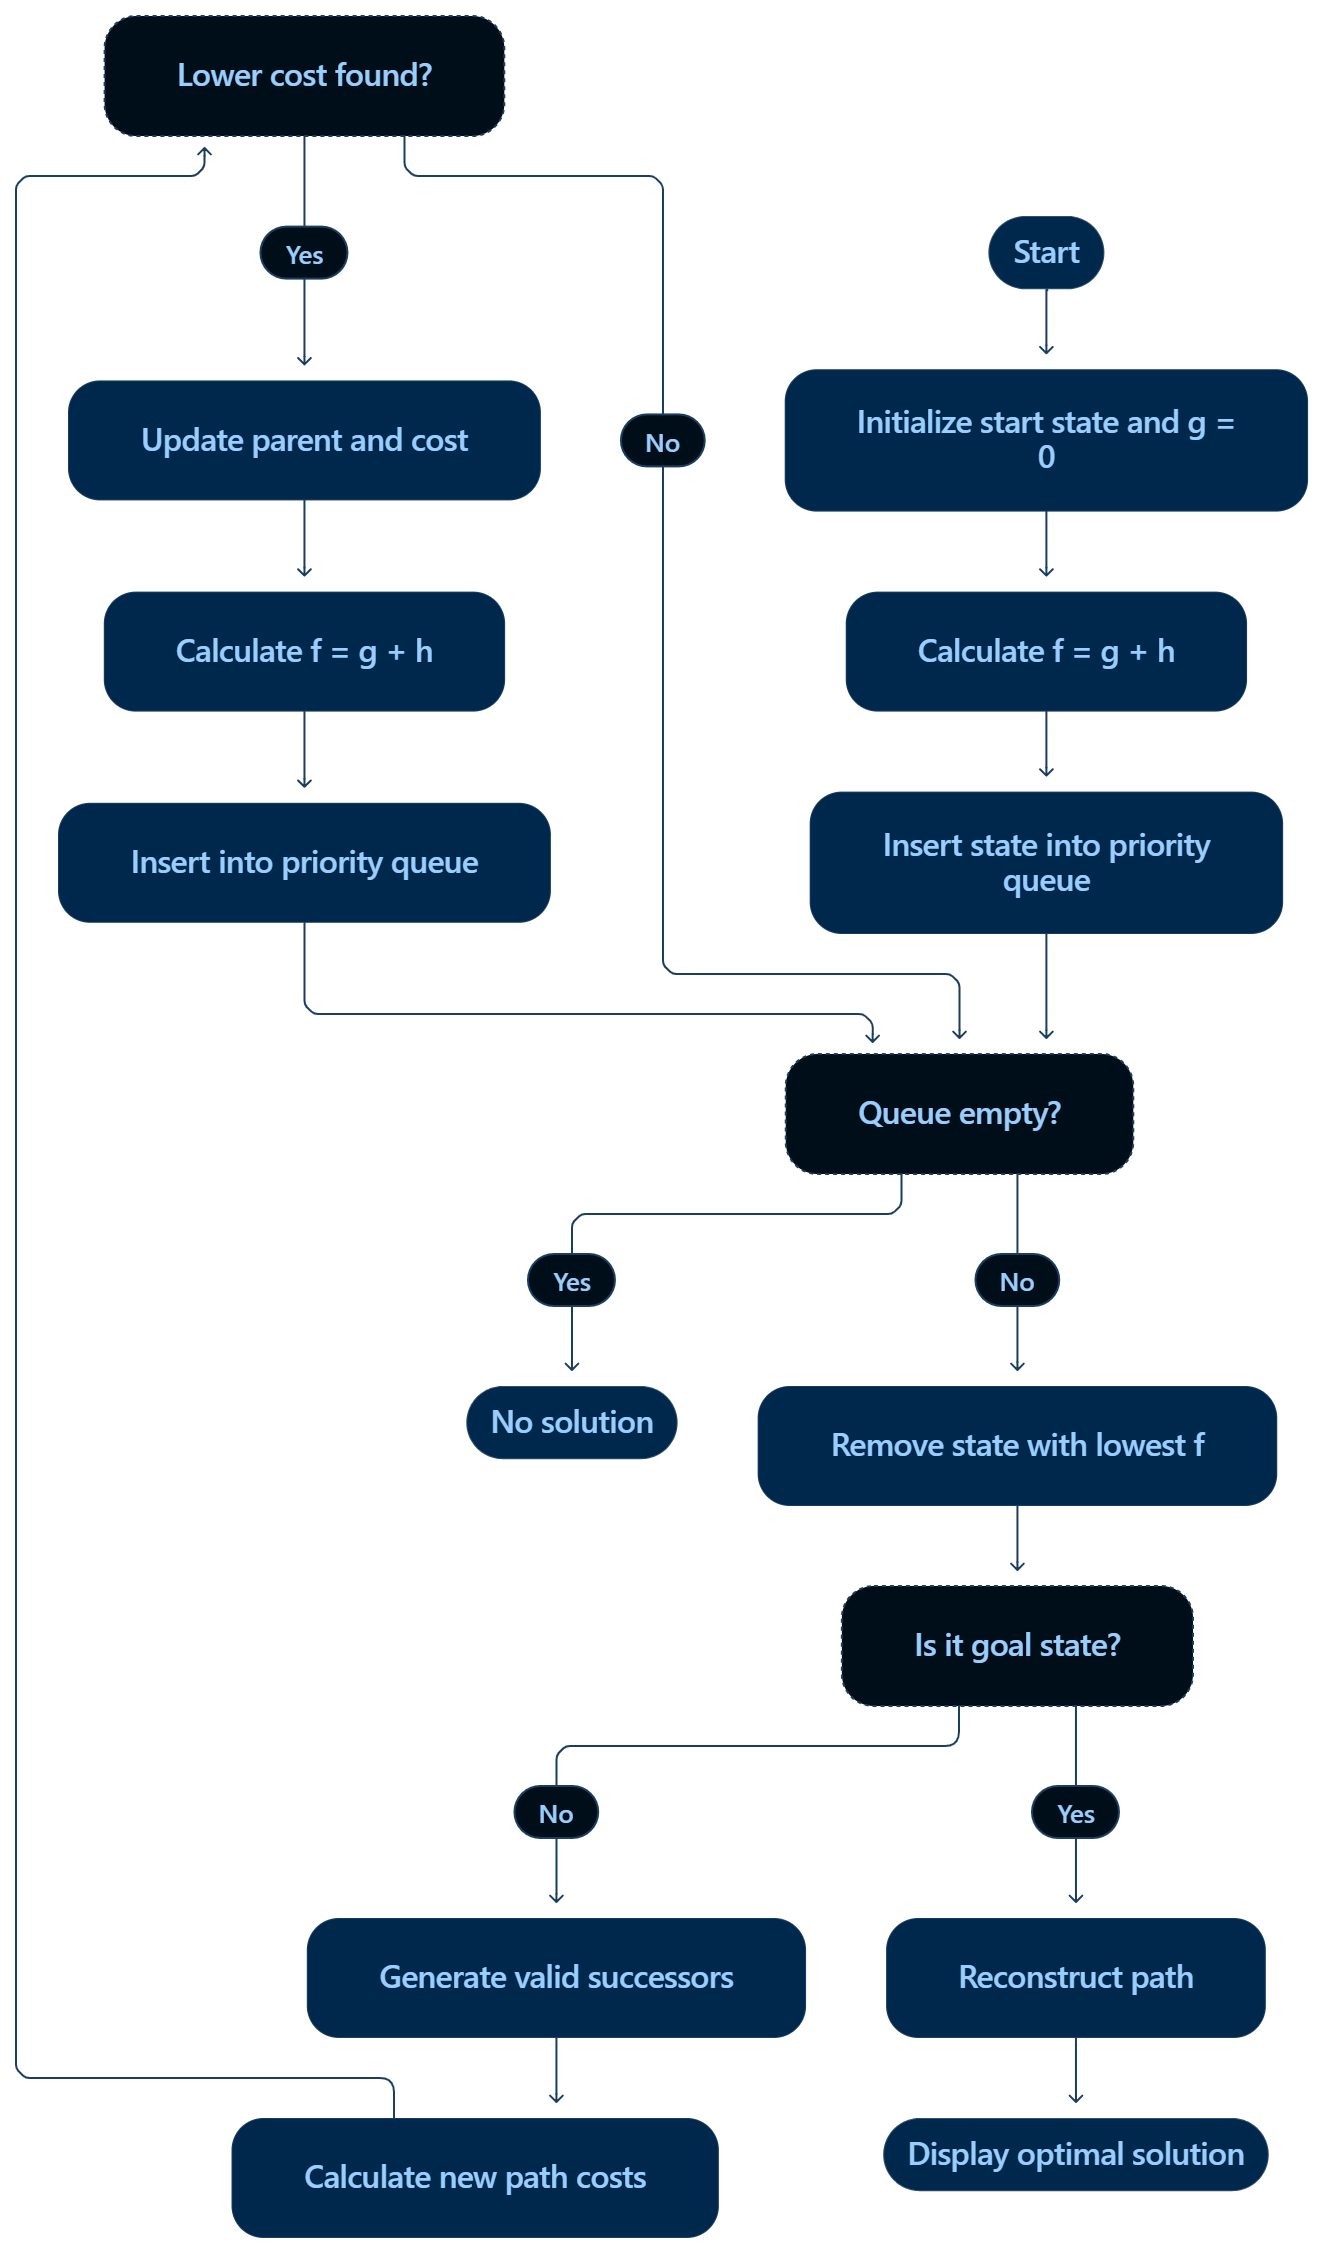

In [ ]:
def heuristic(state):

    if len(state.left) == 0:
        return 0

    return max(
        people[p]
        for p in state.left
    )

In [ ]:
def a_star():

    start = State(
        people.keys(),
        "left"
    )

    priority_queue = []

    counter = 0

    heapq.heappush(
        priority_queue,
        (
            heuristic(start),
            0,
            counter,
            start
        )
    )

    parent = {
        start: None
    }

    move = {}

    cost_so_far = {
        start: 0
    }

    while priority_queue:

        f, current_cost, _, current = \
            heapq.heappop(priority_queue)

        if current_cost != cost_so_far[current]:

            continue

        if current.is_goal():

            return parent, move, current

        for child, cost, group in successors(current):

            new_cost = (
                current_cost + cost
            )

            if (
                child not in cost_so_far
                or new_cost < cost_so_far[child]
            ):

                cost_so_far[child] = new_cost

                parent[child] = current

                move[child] = (
                    group,
                    cost
                )

                counter += 1

                priority = (
                    new_cost
                    + heuristic(child)
                )

                heapq.heappush(
                    priority_queue,
                    (
                        priority,
                        new_cost,
                        counter,
                        child
                    )
                )

    return parent, move, None

In [ ]:
parent, move, goal = a_star()

astar_result = print_solution(
    "A*",
    parent,
    move,
    goal
)


A*

State 0
Left={ABCD}, Right={}, Torch=left

State 1
Left={CD}, Right={AB}, Torch=right
Move: A, B Left -> Right (2 minutes)

State 2
Left={ACD}, Right={B}, Torch=left
Move: A Right -> Left (1 minutes)

State 3
Left={A}, Right={BCD}, Torch=right
Move: C, D Left -> Right (10 minutes)

State 4
Left={AB}, Right={CD}, Torch=left
Move: B Right -> Left (2 minutes)

State 5
Left={}, Right={ABCD}, Torch=right
Move: A, B Left -> Right (2 minutes)

Total Crossing Time: 17 minutes
Number of Crossings: 5


A* successfully reaches the goal state with a total crossing time of 17 minutes. By considering both the actual cost and the estimated remaining cost, it finds a lower-cost solution than the BFS, DFS, DLS and IDDFS paths recorded in the notebook.

# Hill Climbing

**Concept**

Hill Climbing
is a local search technique that moves from the current state to a neighboring state that appears better according to a heuristic function.

Unlike BFS and DFS, Hill Climbing does not maintain a search tree or explore alternative paths systematically. It selects a promising next state and continues from there.

Hill Climbing may become stuck at a local optimum, plateau or dead end, and it does not guarantee finding a solution.

**Working**

Initialize the current state as the starting state.

Calculate the heuristic value of the current state.

Generate all valid neighboring states.

Select the neighbor with the best heuristic value and move cost according to the implementation.

Check whether the neighbor is already visited or fails to improve the heuristic.

If it does not improve, stop the search.

Otherwise, move to the selected neighbor and repeat until the goal is reached or the search gets stuck.

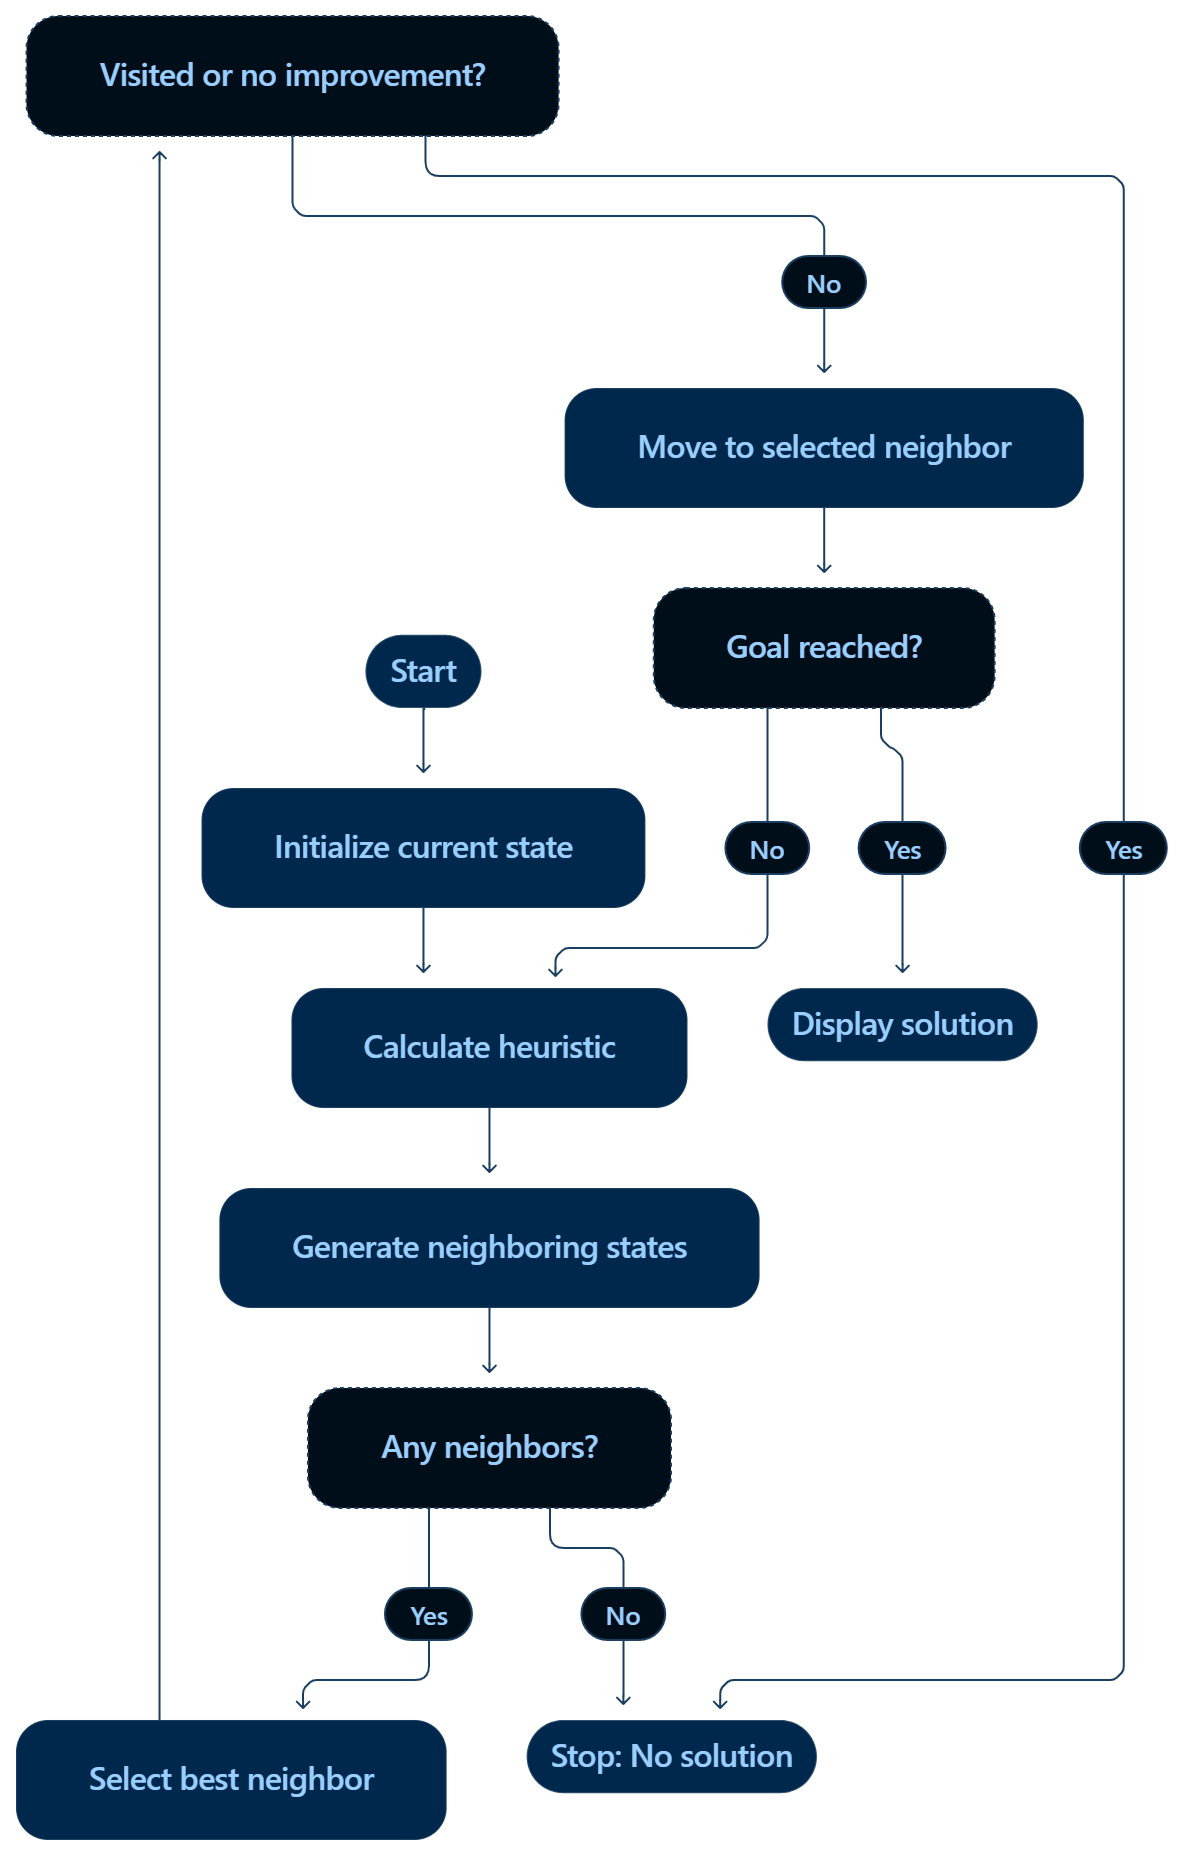

In [ ]:
def hill_climbing():

    current = State(
        people.keys(),
        "left"
    )

    parent = {
        current: None
    }

    move = {}

    visited = {
        current
    }

    while not current.is_goal():

        neighbors = successors(current)

        if not neighbors:
            break

        best = min(
            neighbors,
            key=lambda x: (
                heuristic(x[0]),
                x[1]
            )
        )

        child, cost, group = best

        if (
            child in visited
            or heuristic(child)
            >= heuristic(current)
        ):

            break

        parent[child] = current

        move[child] = (
            group,
            cost
        )

        visited.add(child)

        current = child

    goal = (
        current
        if current.is_goal()
        else None
    )

    return parent, move, goal

In [ ]:
parent, move, goal = hill_climbing()

hill_result = print_solution(
    "Hill Climbing",
    parent,
    move,
    goal
)


Hill Climbing
No solution found.


**Conclusion**

Hill Climbing failed to solve the Bridge and Torch Problem in the provided implementation. Its greedy selection and strict improvement condition can prevent it from exploring states that temporarily appear worse but are necessary to reach the goal.

# Genetic Algorithm

**Concept**

Genetic Algorithm
is a population-based optimization technique inspired by natural selection and biological evolution.

Instead of exploring states one by one, it maintains a population of candidate solutions, called chromosomes. Each chromosome represents a sequence of possible crossing actions.

The algorithm evaluates each chromosome using a fitness function and improves the population over multiple generations through:

Selection: Choosing higher-fitness candidates as parents.

Crossover: Combining parts of two parent chromosomes to create offspring.

Mutation: Randomly changing an action to introduce diversity.

Fitness evaluation: Assigning scores based on the validity of the sequence, whether it reaches the goal, and its total crossing cost.

In the provided notebook, the population size is 100, the number of generations is 200, and the chromosome length is 7.

**Working**

Generate an initial population of random chromosomes.

Simulate each chromosome to evaluate its validity and cost.

Calculate the fitness of every candidate.

Sort candidates based on fitness.

Retain a selection of high-fitness candidates.

Select parents and perform crossover to produce offspring.

Apply mutation to some offspring.

Create the next generation.

Repeat the process for the specified number of generations.

Return the best candidate found and check whether it reaches the goal.

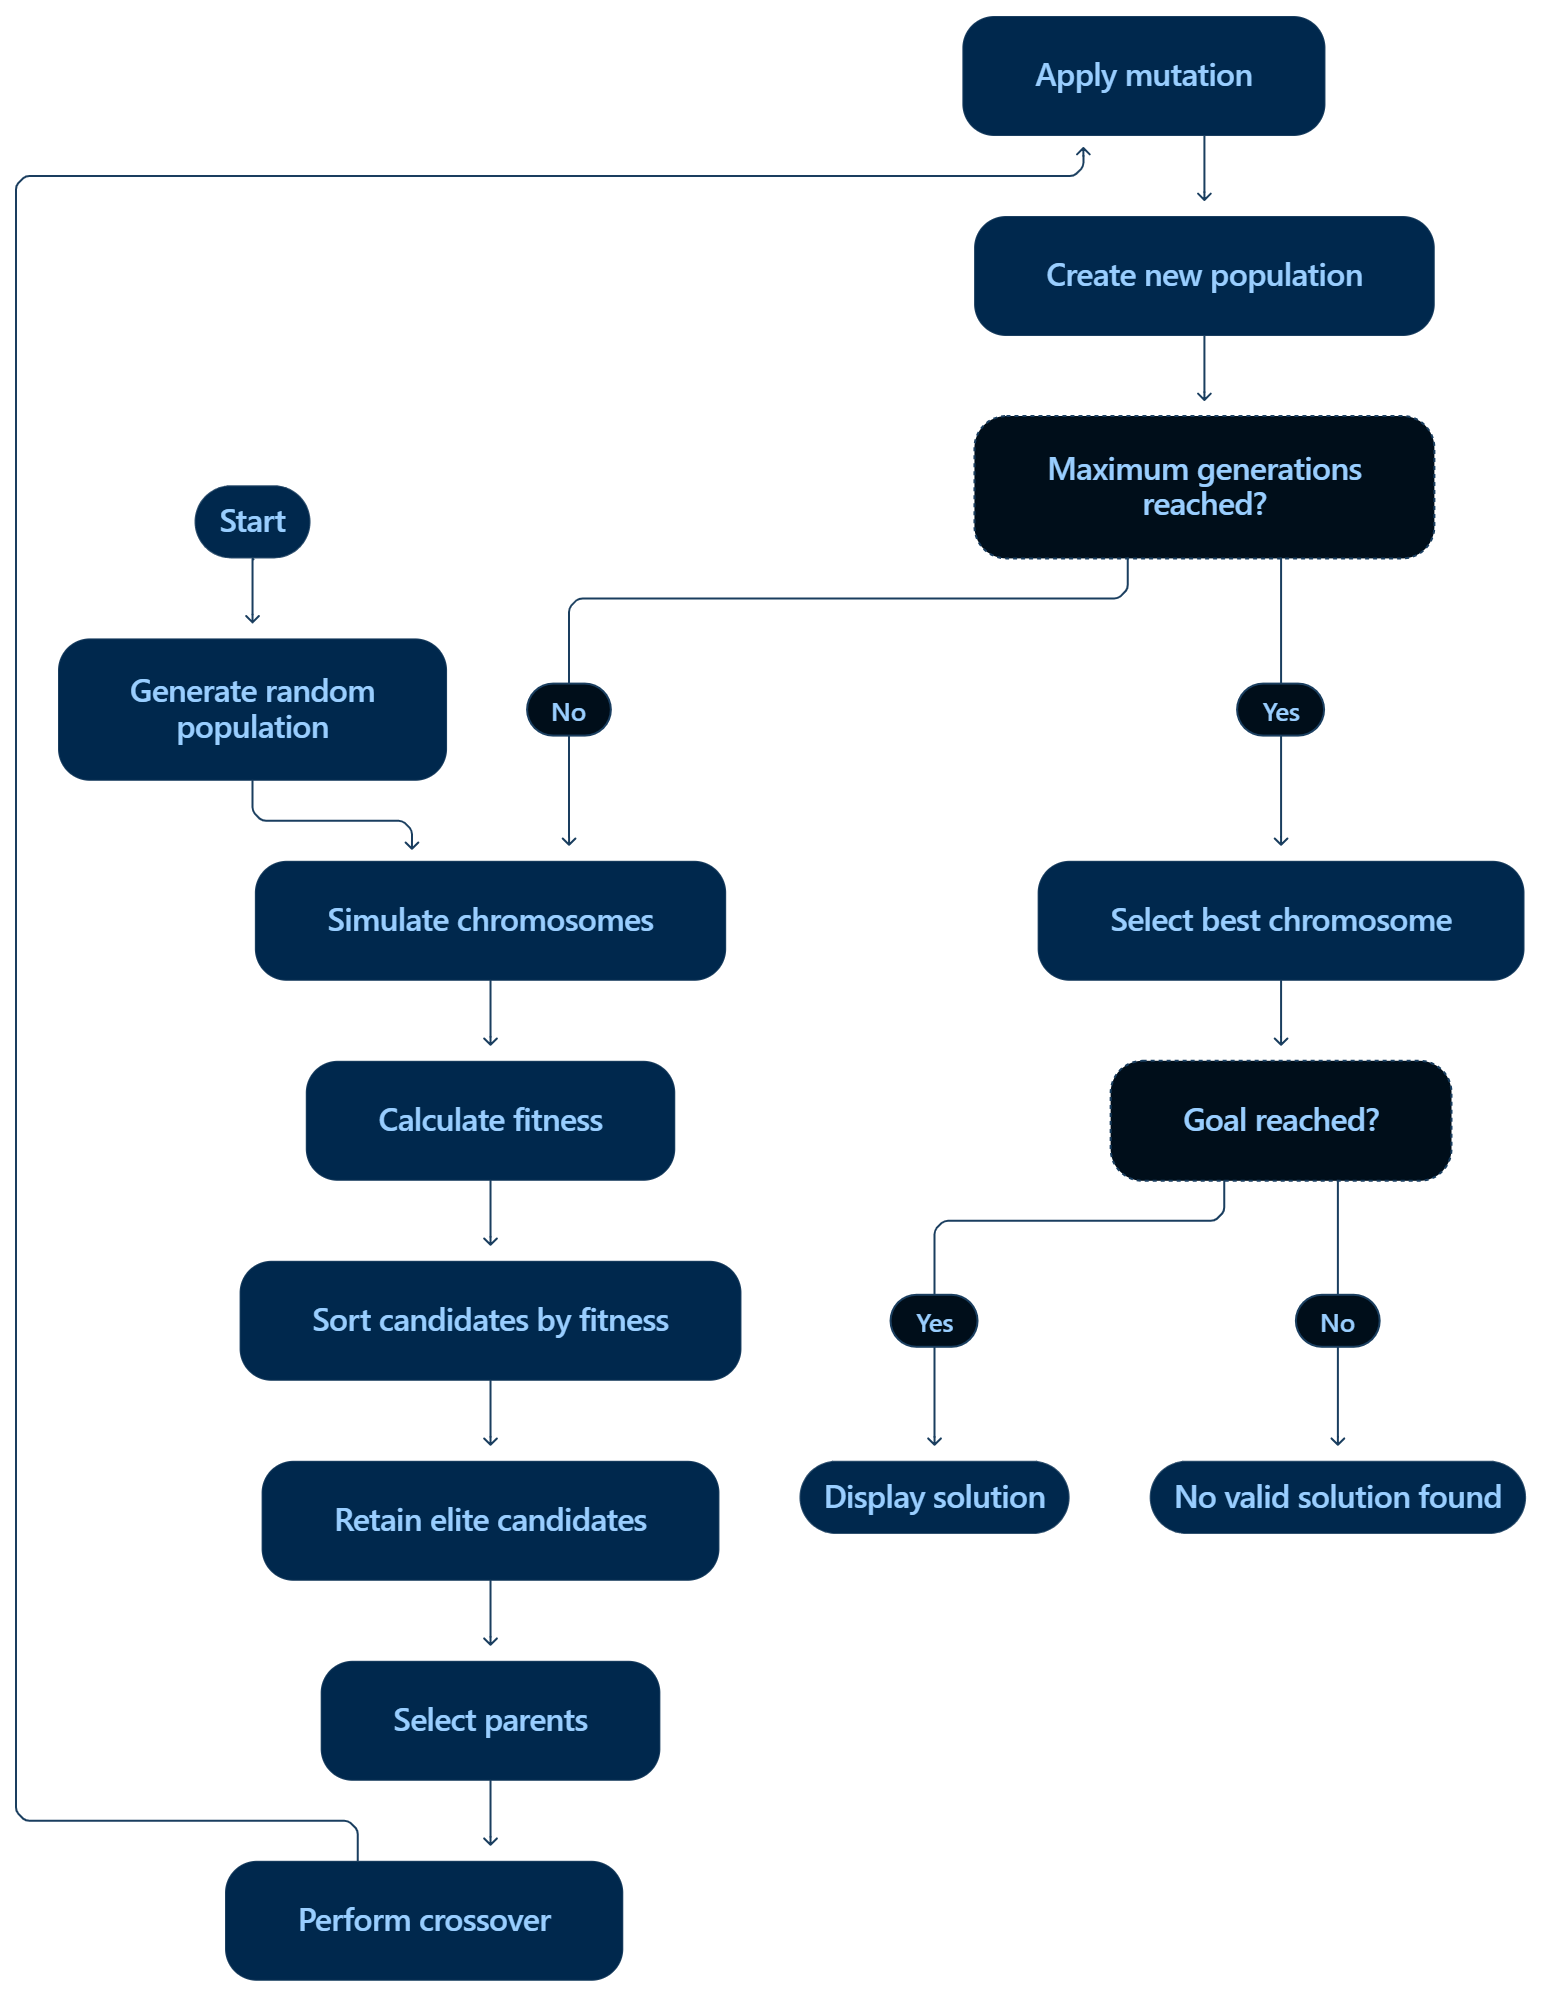

In [ ]:
actions = [
    tuple(x)
    for r in [1, 2]
    for x in itertools.combinations(
        people.keys(),
        r
    )
]

In [ ]:
def simulate_sequence(sequence):

    state = State(
        people.keys(),
        "left"
    )

    total_cost = 0

    for action in sequence:

        valid_moves = successors(state)

        selected = None

        for child, cost, group in valid_moves:

            if set(group) == set(action):

                selected = (
                    child,
                    cost
                )

                break

        if selected is None:

            return None, float("inf")

        state = selected[0]

        total_cost += selected[1]

    return state, total_cost

In [ ]:
def simulate_sequence(sequence):

    state = State(
        people.keys(),
        "left"
    )

    total_cost = 0

    for action in sequence:

        valid_moves = successors(state)

        selected = None

        for child, cost, group in valid_moves:

            if set(group) == set(action):

                selected = (
                    child,
                    cost
                )

                break

        if selected is None:

            return None, float("inf")

        state = selected[0]

        total_cost += selected[1]

    return state, total_cost

In [ ]:
def fitness(sequence):

    state, cost = simulate_sequence(
        sequence
    )

    if state is None:

        return 0

    if state.is_goal():

        return 1000 - cost

    return 1 / (1 + cost)

In [ ]:
def genetic_algorithm(
    population_size=100,
    generations=200,
    chromosome_length=7
):

    population = []

    for _ in range(
        population_size
    ):

        chromosome = [
            random.choice(actions)
            for _ in range(
                chromosome_length
            )
        ]

        population.append(chromosome)

    best_solution = None
    best_fitness = float("-inf")

    for generation in range(generations):

        scored = [
            (
                fitness(chromosome),
                chromosome
            )
            for chromosome in population
        ]

        scored.sort(
            reverse=True,
            key=lambda x: x[0]
        )

        if scored[0][0] > best_fitness:

            best_fitness = scored[0][0]

            best_solution = scored[0][1]

        new_population = [
            chromosome
            for _, chromosome
            in scored[:10]
        ]

        while len(new_population) < population_size:

            parent1 = random.choice(
                scored[:30]
            )[1]

            parent2 = random.choice(
                scored[:30]
            )[1]

            point = random.randint(
                1,
                chromosome_length - 1
            )

            child = (
                parent1[:point]
                + parent2[point:]
            )

            if random.random() < 0.1:

                index = random.randrange(
                    chromosome_length
                )

                child[index] = random.choice(
                    actions
                )

            new_population.append(child)

        population = new_population

    return best_solution

In [ ]:
ga_solution = genetic_algorithm()

print("Genetic Algorithm Result")

print("=" * 50)

if ga_solution:

    state, cost = simulate_sequence(
        ga_solution
    )

    print(
        "Chromosome:",
        ga_solution
    )

    print(
        "Total Cost:",
        cost
    )

    print(
        "Goal Reached:",
        state.is_goal()
        if state
        else False
    )

Genetic Algorithm Result
Chromosome: [('A', 'B'), ('A',), ('C', 'D'), ('B',), ('A', 'B'), ('C',), ('C',)]
Total Cost: 27
Goal Reached: True


**Conclusion**

The Genetic Algorithm successfully found a valid solution with a total crossing cost of 27 minutes in the recorded run. It demonstrates how evolutionary optimization can find a valid sequence, but its stochastic nature and fitness-based search do not guarantee the minimum crossing time.

# Constraint Satisfaction Problem (CSP)

**CSP Formulation**

A CSP consists of three main components:

Variables: The decisions that need to be made.

Domains: The possible values assigned to each variable.

Constraints: The rules that every assignment must satisfy.

In [1]:

from itertools import combinations

people = {
    "A": 1,
    "B": 2,
    "C": 5,
    "D": 10
}

# Five crossing variables: M1 to M5
N = 5

best_cost = float("inf")
best_path = []
valid_solutions = 0

def csp(left, step, total_time, path):
    global best_cost, best_path, valid_solutions

    # Constraint: Do not explore costlier paths
    if total_time >= best_cost:
        return

    # All five crossing variables assigned
    if step == N:
        if len(left) == 0:
            valid_solutions += 1
            best_cost = total_time
            best_path = path.copy()
        return

    # Torch alternates sides
    if step % 2 == 0:
        available = sorted(left)
        direction = "Left -> Right"
    else:
        available = sorted(set(people) - left)
        direction = "Right -> Left"

    # Domain: groups of one or two people
    for size in [1, 2]:
        for group in combinations(available, size):

            # Apply crossing constraints
            new_left = set(left)

            if direction == "Left -> Right":
                new_left.difference_update(group)
            else:
                new_left.update(group)

            # Cost is determined by the slower person
            cost = max(people[p] for p in group)

            # Assign variable Mi and continue
            path.append((step + 1, group, direction, cost))

            csp(
                new_left,
                step + 1,
                total_time + cost,
                path
            )

            # Backtrack
            path.pop()


# Initial state
csp(set(people.keys()), 0, 0, [])

# Display solution
print("CSP Solution")
print("-" * 40)

for move, group, direction, cost in best_path:
    print(
        f"M{move}: {', '.join(group)} "
        f"| {direction} | {cost} minutes"
    )

print("-" * 40)
print("Total Crossing Time:", best_cost, "minutes")
print("Number of Crossings:", len(best_path))

CSP Solution
----------------------------------------
M1: A, B | Left -> Right | 2 minutes
M2: A | Right -> Left | 1 minutes
M3: C, D | Left -> Right | 10 minutes
M4: B | Right -> Left | 2 minutes
M5: A, B | Left -> Right | 2 minutes
----------------------------------------
Total Crossing Time: 17 minutes
Number of Crossings: 5


**Conclusion**

The Bridge and Torch Problem can be represented as a CSP by defining crossing variables, their possible domains and constraints. Backtracking assigns possible crossing groups and rejects assignments that violate the rules.

The CSP-based approach finds a valid solution with a total crossing time of 17 minutes and 5 crossings, matching the optimal result shown by A* in your assignment.

# Overall Conclusion

The experiment demonstrates the application of different Artificial Intelligence search algorithms to the Bridge and Torch Problem. Each algorithm follows a different strategy for exploring the state space and finding a path from the initial state to the goal state.

BFS and IDDFS both found solutions with five crossings and a total time of 19 minutes, while DFS and DLS found valid but higher-cost solutions. The Bidirectional Search implementation failed to reconstruct a valid path, and Hill Climbing stopped without reaching the goal. The Genetic Algorithm found a valid solution with a total cost of 27 minutes in the recorded run.

A* Search found a valid solution with a total crossing time of 17 minutes, using the actual cost of each move along with a heuristic estimate. This matches the minimum possible crossing time for the given problem.

The experiment illustrates the importance of selecting a search strategy according to the problem's requirements, especially when the objective involves minimizing cost rather than simply reaching the goal.